In [13]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, homogeneity_score
from sklearn.datasets import load_files
from sklearn.feature_extraction.text import TfidfVectorizer

## 1. Произведите методом k-means кластеризацию вин (датасет возьмите из третьей работы). Произведите разные варианты инициализации центров. Сравните результат. 

In [14]:
df = pd.read_csv("winequality-red.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [15]:
df["status"] = (df["quality"] >= 7).astype(int)

features = [
    'fixed acidity', 
    'volatile acidity', 
    'citric acid', 
    'residual sugar',
    'chlorides', 
    'free sulfur dioxide', 
    'total sulfur dioxide', 
    'density',
    'pH', 
    'sulphates', 
    'alcohol'
]

X, y = df[features], df["status"]
X, y = X.to_numpy(), y.to_numpy()

In [16]:
kmeans_pp_model = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)
kmeans_pp_model.fit(X)
print("ARI (k-means++):", adjusted_rand_score(y, kmeans_pp_model.labels_))

kmeans_rand_model = KMeans(n_clusters=3, init='random', n_init=10, random_state=42)
kmeans_rand_model.fit(X)
print("ARI (random):", adjusted_rand_score(y, kmeans_rand_model.labels_))

ARI (k-means++): -0.029781829393187857
ARI (random): -0.024445098629697848


## 2. Выберите черно-белое и цветное изображение. Сожмите изображение с помощью метода K-means. 

In [17]:
img = mpimg.imread('woman.jpg')
X = img.reshape(-1, 3)

In [18]:
km_model = KMeans(n_clusters=16, random_state=42)
km_model.fit(X)
labels = km_model.labels_
values = km_model.cluster_centers_
img_compressed = values[labels].reshape(img.shape)

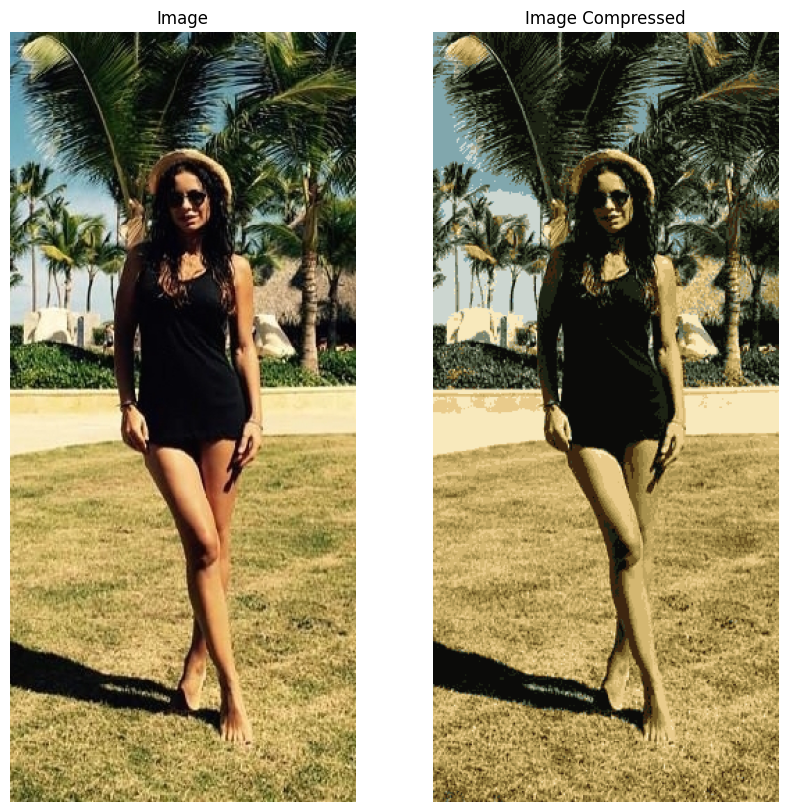

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 10))

axes[0].imshow(img.astype(np.uint8))
axes[0].set_title("Image")
axes[0].axis('off')

axes[1].imshow(img_compressed.astype(np.uint8))
axes[1].set_title("Image Compressed")
axes[1].axis('off')

plt.show()

## 3. Применим KMeans для кластеризации текстов.

In [20]:
dataset = load_files("KMeans/20_Newsgroups", encoding='latin1', decode_error='ignore')
X, y = dataset.data, dataset.target
true_k = len(np.unique(y))

In [21]:
vectorizer = TfidfVectorizer(max_df=0.5, max_features=2000, min_df=2, stop_words='english')
X_tfidf = vectorizer.fit_transform(X)

In [22]:
km_model = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=10, random_state=42)
km_model.fit(X_tfidf)

,n_clusters,20
,init,'k-means++'
,n_init,10
,max_iter,100
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [23]:
print("ARI:", adjusted_rand_score(y, km_model.labels_))
print("Homogeneity:", homogeneity_score(y, km_model.labels_))

ARI: 0.18138243759198758
Homogeneity: 0.37608882057687687


In [24]:
terms = vectorizer.get_feature_names_out()
order_centroids = km_model.cluster_centers_.argsort()[:, ::-1]
for i in range(true_k):
    print("Cluster %d:" % i, end='')
    for ind in order_centroids[i, :10]:
        print(' %s' % terms[ind], end='')
    print()

Cluster 0: rec state ohio hp cc sci article nntp mps posting
Cluster 1: rutgers christian athos geneva god religion soc igor hedrick aramis
Cluster 2: sys ibm comp mac hardware pc drive scsi graphics card
Cluster 3: culture soc turkish armenian soviet armenians politics mideast zuma armenia
Cluster 4: fi se ericsson mcsun comp uunet pipex nntp usenet mac
Cluster 5: magnus acs ohio state autos university misc rec article forsale
Cluster 6: netcom clipper crypt security org key encryption sci eff chip
Cluster 7: ca bnr ubc canada bc hockey rec uwaterloo ohio state
Cluster 8: windows os comp ms misc dos apps file motif microsoft
Cluster 9: au oz munnari australia monash cc comp org batcomputer mq
Cluster 10: forsale misc cwru sale cleveland ins computers freenet usenet ohio
Cluster 11: sgi mchp sni ap horus frank objective livesey fido morality
Cluster 12: mit enterpoop athena lcs internet senator ai gateway windows 0400
Cluster 13: talk politics misc alt religion people guns state ohio i